In [42]:
import sys 
import seaborn as sns
print(sys.version)
print(sns.__version__)

3.9.1 (tags/v3.9.1:1e5d33e, Dec  7 2020, 17:08:21) [MSC v.1927 64 bit (AMD64)]
0.13.2


In [43]:
import sys
print(sys.executable)

e:\ai resume analyzer\venv\Scripts\python.exe


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv("Resume.csv")

In [46]:
df

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR
...,...,...,...,...
2479,99416532,RANK: SGT/E-5 NON- COMMISSIONED OFFIC...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2480,24589765,"GOVERNMENT RELATIONS, COMMUNICATIONS ...","<div class=""fontsize fontface vmargins hmargin...",AVIATION
2481,31605080,GEEK SQUAD AGENT Professional...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2482,21190805,PROGRAM DIRECTOR / OFFICE MANAGER ...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION


In [47]:
df["Resume_length"] = df ["Resume_str"].apply(len)

In [48]:
df["Resume_length"].describe

<bound method NDFrame.describe of 0       5442
1       5572
2       7720
3       2855
4       9172
        ... 
2479    5533
2480    7108
2481    2020
2482    5074
2483    5234
Name: Resume_length, Length: 2484, dtype: int64>

<function matplotlib.pyplot.show(close=None, block=None)>

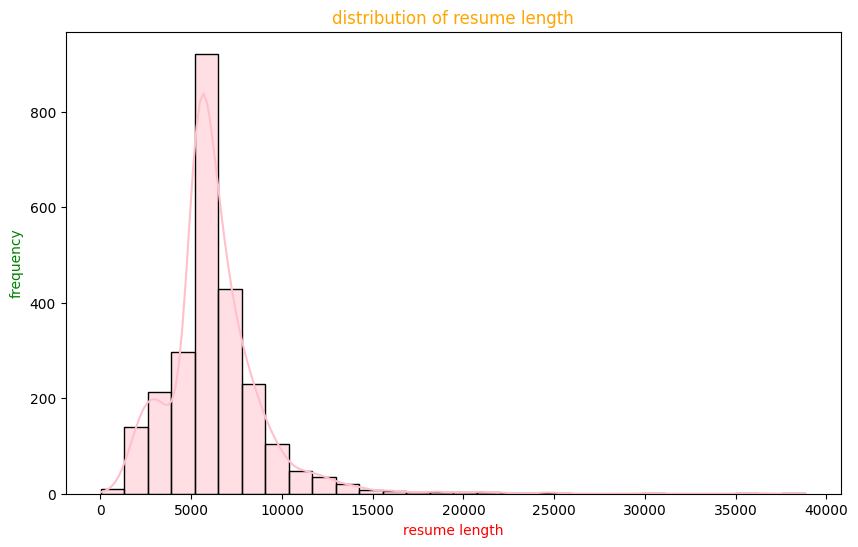

In [49]:
plt.figure(figsize=(10,6))
sns.histplot(df["Resume_length"], bins=30, kde=True, color="pink")
plt.title("distribution of resume length", color="orange")
plt.xlabel("resume length", color="red")
plt.ylabel("frequency", color="green")
plt.show

C:\Users\Admin\AppData\Local\Temp\ipykernel_13904\3494004166.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


<function matplotlib.pyplot.show(close=None, block=None)>

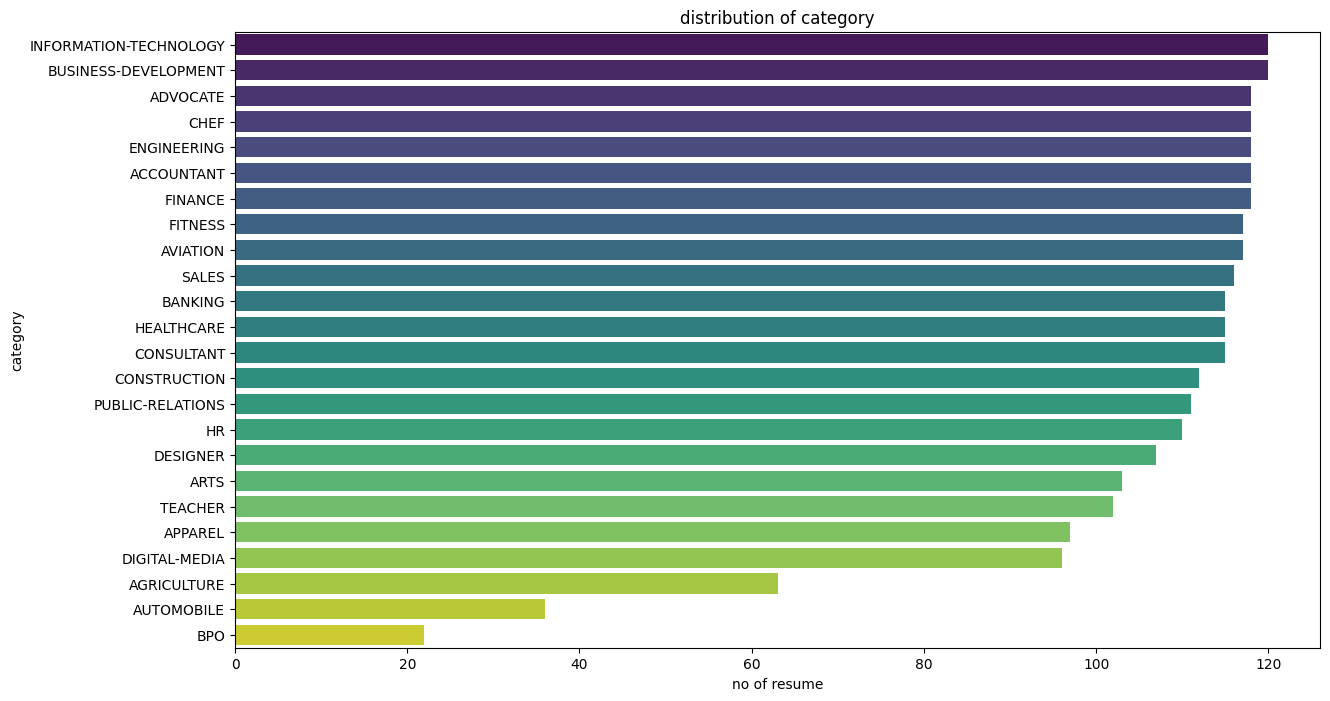

In [50]:
plt.figure(figsize=(14,8))
sns.countplot(
  y=df["Category"],
  order=df["Category"].value_counts().index,
  palette="viridis"
)
plt.title("distribution of category")
plt.xlabel("no of resume")
plt.ylabel("category")

plt.show

In [51]:
df['word_count'] = df['Resume_str'].apply(lambda x: len(x.split()))

In [52]:
df['word_count'].describe()

count    2484.000000
mean      811.325684
std       371.006906
min         0.000000
25%       651.000000
50%       757.000000
75%       933.000000
max      5190.000000
Name: word_count, dtype: float64

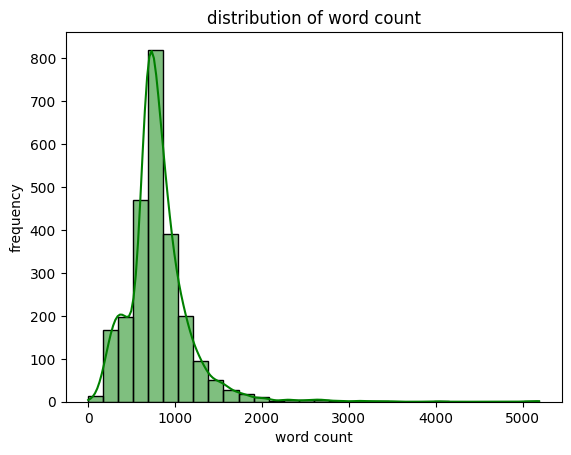

In [53]:
plt.Figure(figsize=(10,6))
sns.histplot(df['word_count'], bins=30, kde=True, color='green')
plt.title("distribution of word count")
plt.xlabel("word count")
plt.ylabel("frequency")

plt.show()

In [54]:
import re

In [55]:
def clean_resume(text):
  text = re.sub(r"http\S+", " ", text)
  text = re.sub(r"\S+@\S", " ", text)
  text = re.sub(r"\+?\d[\d\s-]{8, }\d", " ", text)
  text = re.sub(r"[^a-zA-Z]", " ", text)
  text = text.lower()
  text = re.sub(r"\s+", " ", text).strip()
  return text

In [56]:
df['clean_resume'] = df['Resume_str'].apply(clean_resume)

In [57]:
df[["Resume_str", "clean_resume"]].head()

,Resume_str,clean_resume
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,hr administrator marketing associate hr admini...
1,"HR SPECIALIST, US HR OPERATIONS ...",hr specialist us hr operations summary versati...
2,HR DIRECTOR Summary Over 2...,hr director summary over years experience in r...
3,HR SPECIALIST Summary Dedica...,hr specialist summary dedicated driven and dyn...
4,HR MANAGER Skill Highlights ...,hr manager skill highlights hr skills hr depar...


In [58]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [59]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
 
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [60]:
def preprocess_text(text):
  words = nltk.word_tokenize(text)

  words = [
    lemmatizer.lemmatize(word)
    for word in words
    if word.isalpha() and word not in stop_words
  ]
  return " ".join(words)
  

In [61]:
df["processed_resume"] =df["clean_resume"].apply(preprocess_text)

In [62]:
import nltk
print(nltk.__version__)

3.9.2


In [63]:
df[["clean_resume", "processed_resume"]].head()

,clean_resume,processed_resume
0,hr administrator marketing associate hr admini...,hr administrator marketing associate hr admini...
1,hr specialist us hr operations summary versati...,hr specialist u hr operation summary versatile...
2,hr director summary over years experience in r...,hr director summary year experience recruiting...
3,hr specialist summary dedicated driven and dyn...,hr specialist summary dedicated driven dynamic...
4,hr manager skill highlights hr skills hr depar...,hr manager skill highlight hr skill hr departm...


In [64]:

from sklearn.feature_extraction.text import TfidfVectorizer

In [81]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
  max_features=5000,
  stop_words="english"
)
x=tfidf.fit_transform(df["processed_resume"])
y= df['Category']

In [66]:
from sklearn.model_selection import train_test_split

x_train, x_test,y_train, y_test= train_test_split(
  x,
  y,
  test_size=0.2,
  random_state=42,
  stratify=y
)

In [67]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)

LogisticRegression(max_iter=1000)

In [68]:
print(type(model))

<class 'sklearn.linear_model._logistic.LogisticRegression'>


In [69]:
y_pred=model.predict(x_test)
print(y_pred[:5])

['ARTS' 'DIGITAL-MEDIA' 'CONSTRUCTION' 'HEALTHCARE' 'CONSTRUCTION']


In [70]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy: ",accuracy)

Accuracy:  0.6519114688128773


In [71]:
from sklearn.metrics import  classification_report

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

                        precision    recall  f1-score   support

            ACCOUNTANT       0.65      0.83      0.73        24
              ADVOCATE       0.38      0.50      0.43        24
           AGRICULTURE       1.00      0.46      0.63        13
               APPAREL       0.60      0.16      0.25        19
                  ARTS       0.42      0.24      0.30        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.82      0.75      0.78        24
               BANKING       0.84      0.70      0.76        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.47      0.79      0.59        24
                  CHEF       0.81      0.71      0.76        24
          CONSTRUCTION       0.81      0.77      0.79        22
            CONSULTANT       0.50      0.17      0.26        23
              DESIGNER       0.81      0.81      0.81        21
         DIGIT

e:\ai resume analyzer\venv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
e:\ai resume analyzer\venv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
e:\ai resume analyzer\venv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [72]:
print(df['Category'].nunique())
print(df['Category'].value_counts())

24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [73]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
nb_model = MultinomialNB()
nb_model.fit(x_train, y_train)
nb_pred = nb_model.predict(x_test)
print("naive bayes accuracy: ", accuracy_score(y_test, nb_pred))

naive bayes accuracy:  0.5472837022132797


In [84]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC()
svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)
print("linear svm accuracy:", accuracy_score(y_test, svm_pred))

linear svm accuracy: 0.7122736418511066


In [82]:
tfidf = TfidfVectorizer(
  max_features=5000,
  ngram_range=(1,2),
  min_df=2,
  max_df=0.95,
  sublinear_tf=True,
  stop_words="english"
)
x = tfidf.fit_transform(df["processed_resume"])

In [86]:
import joblib
joblib.dump(svm_model, "resume_classifier.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("model and vectorizer saved successfully!")

model and vectorizer saved successfully!


In [79]:
print(tfidf)
print(hasattr(tfidf, "vocabulary_"))

TfidfVectorizer(max_df=0.95, max_features=10000, min_df=2, ngram_range=(1, 2),
                stop_words='english', sublinear_tf=True)
True
